# The US Gini coefficient, 1947–2025

**What this notebook does:** loads the Census family-income Gini index (FRED series `GINIALLRF`), checks the data, describes the long-run trend, and saves a chart plus a small file of key numbers that the project website reads.

**What the Gini coefficient is:** a single number summarising how unequally income is shared.

* **0** = every family has exactly the same income.
* **1** = one family has all the income.
* US family income sits around **0.35–0.46** over this period. A rise of 0.01 is a meaningful change; here we usually multiply by 100 and talk about *index points* (0.376 → 37.6).

**Run it:** *Runtime → Run all*. In Colab it clones the project repo first; locally it uses the repo it sits in.

## 1. Setup

In [1]:
import json, pathlib, subprocess, sys

REPO_URL = "https://github.com/jvelaise/us-inequality-macro"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = pathlib.Path("/content/us-inequality-macro")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
else:
    # notebooks/ sits one level below the repo root
    here = pathlib.Path.cwd()
    ROOT = here.parent if here.name == "notebooks" else here

RAW = ROOT / "data" / "raw" / "GINIALLRF.csv"
OUTDIR = ROOT / "outputs"
OUTDIR.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /home/user/us-inequality-macro


## 2. (Optional) refresh the data from FRED

Leave `REFRESH = False` to use the copy saved in the repo, so results are reproducible. Set it to `True` in Colab to download the latest vintage. If the download fails, the notebook keeps the saved copy and tells you.

In [2]:
REFRESH = False
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=GINIALLRF"

if REFRESH:
    import urllib.request
    try:
        tmp = RAW.with_suffix(".download.csv")
        urllib.request.urlretrieve(FRED_URL, tmp)
        header = tmp.read_text().splitlines()[0]
        assert "GINIALLRF" in header, f"unexpected header: {header}"
        tmp.replace(RAW)
        print("refreshed", RAW.name)
    except Exception as e:
        print("refresh failed, keeping saved copy:", e)

## 3. Load and check

The checks stop the notebook with a clear message if the file is wrong (missing years, values off the 0–1 scale, duplicates), rather than producing a chart that looks fine but isn't.

In [3]:
import pandas as pd

df = pd.read_csv(RAW)
df["year"] = pd.to_datetime(df["observation_date"]).dt.year
gini = df.set_index("year")["GINIALLRF"].rename("gini")

assert gini.notna().all(), "missing Gini values"
assert gini.index.is_unique, "duplicate years"
assert gini.between(0.2, 0.7).all(), "values outside plausible 0-1 Gini range"
missing = sorted(set(range(gini.index.min(), gini.index.max() + 1)) - set(gini.index))
assert not missing, f"gap in years: {missing}"

g100 = gini * 100   # index points
print(f"{len(gini)} years, {gini.index.min()}-{gini.index.max()}; all checks passed")
g100.tail()

79 years, 1947-2025; all checks passed


year
2021    46.2
2022    45.8
2023    45.2
2024    45.7
2025    46.0
Name: gini, dtype: float64

## 4. Key numbers

In [4]:
import numpy as np

def slope_per_decade(s):
    """Least-squares trend, in index points per 10 years."""
    return float(np.polyfit(s.index, s.values, 1)[0] * 10)

y0, y1 = int(g100.index.min()), int(g100.index.max())
low_year = int(g100.idxmin())
jumps = g100.diff().dropna()

summary = {
    "series": "GINIALLRF (Census, families)",
    "first_year": y0, "first_value": round(float(g100.iloc[0]), 1),
    "last_year": y1, "last_value": round(float(g100.iloc[-1]), 1),
    "low_year": low_year, "low_value": round(float(g100.min()), 1),
    "rise_since_low": round(float(g100.iloc[-1] - g100.min()), 1),
    "rise_total": round(float(g100.iloc[-1] - g100.iloc[0]), 1),
    "trend_before_low_per_decade": round(slope_per_decade(g100.loc[:low_year]), 2),
    "trend_after_low_per_decade": round(slope_per_decade(g100.loc[low_year:]), 2),
    "largest_jump_year": int(jumps.idxmax()),
    "largest_jump": round(float(jumps.max()), 1),
}
for k, v in summary.items():
    print(f"{k:30s} {v}")

series                         GINIALLRF (Census, families)
first_year                     1947
first_value                    37.6
last_year                      2025
last_value                     46.0
low_year                       1968
low_value                      34.8
rise_since_low                 11.2
rise_total                     8.4
trend_before_low_per_decade    -0.96
trend_after_low_per_decade     2.19
largest_jump_year              1993
largest_jump                   2.5


**Reading these numbers:** inequality *fell slightly* from 1947 to its low point in the late 1960s, then rose fairly steadily for over five decades. Compare the two trend slopes (index points per decade) before and after the low point.

## 5. Chart: the long-run trend

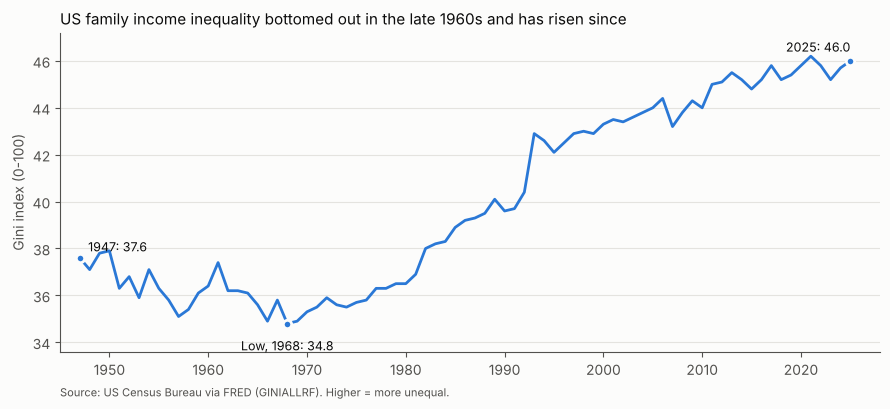

In [5]:
import matplotlib.pyplot as plt

INK, INK2, GRID, LINE, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#fcfcfb"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2})

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(g100.index, g100.values, color=LINE, lw=2, solid_capstyle="round")

# label only the three points the story needs
for yr, txt, ha, off in [(y0, f"{y0}: {g100[y0]:.1f}", "left", (6, 8)),
                         (low_year, f"Low, {low_year}: {g100[low_year]:.1f}", "center", (0, -16)),
                         (y1, f"{y1}: {g100[y1]:.1f}", "right", (0, 10))]:
    ax.plot(yr, g100[yr], "o", ms=6, color=LINE, mec=SURFACE, mew=2, zorder=3)
    ax.annotate(txt, (yr, g100[yr]), xytext=off, textcoords="offset points",
                ha=ha, va="center", fontsize=9, color=INK)
ax.set_ylim(g100.min() - 1.2, g100.max() + 1)

ax.set_title("US family income inequality bottomed out in the late 1960s and has risen since",
             loc="left", color=INK, fontsize=11)
ax.set_ylabel("Gini index (0-100)")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_xlim(y0 - 2, y1 + 3)
ax.text(0, -0.14, "Source: US Census Bureau via FRED (GINIALLRF). Higher = more unequal.",
        transform=ax.transAxes, fontsize=8, color=INK2)
fig.tight_layout()
fig.savefig(OUTDIR / "gini_trend.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
plt.show()

## 6. Decade averages

In [6]:
decades = (g100.groupby((g100.index // 10) * 10).agg(["mean", "min", "max", "count"])
           .round(1).rename_axis("decade"))
decades.index = [f"{d}s" for d in decades.index]
decades

,mean,min,max,count
1940s,37.5,37.1,37.8,3
1950s,36.3,35.1,37.9,10
1960s,35.8,34.8,37.4,10
1970s,35.8,35.3,36.5,10
1980s,38.5,36.5,40.1,10
1990s,41.9,39.6,43.0,10
2000s,43.7,43.2,44.4,10
2010s,45.1,44.0,45.8,10
2020s,45.8,45.2,46.2,6


## 7. Caveat: survey changes, not just real changes

The biggest single-year jump in the series is printed below. Census changed how it collects income data around **1993** (computer-assisted interviews and higher reporting limits for top incomes), which raised measured inequality on its own. A later questionnaire redesign (around 2013–14) is another known break. So part of the post-1980 rise is measurement; the long upward trend survives either way, but **don't attribute the single 1993 jump to the economy**.

In [7]:
print("Largest year-on-year increases (index points):")
jumps.sort_values(ascending=False).head(5).round(1)

Largest year-on-year increases (index points):


year
1993    2.5
1954    1.2
1982    1.1
2011    1.0
1961    1.0
Name: gini, dtype: float64

**Also note:** this is the *family* Gini, which leaves out people living alone. The Census *household* Gini (from 1967) runs a few points higher. Check which one a source uses before comparing numbers.

## 8. Save key numbers for the website

In [8]:
out = OUTDIR / "gini_summary.json"
out.write_text(json.dumps(summary, indent=2))
print("wrote", out.relative_to(ROOT), "and", (OUTDIR / "gini_trend.png").relative_to(ROOT))

wrote outputs/gini_summary.json and outputs/gini_trend.png


## 9. To save your changes back to GitHub (from Colab)

*File → Save a copy in GitHub* → repo `jvelaise/us-inequality-macro`, path `notebooks/gini_coefficient.ipynb`. Outputs written to `/content/...` are temporary: either download them, or rerun locally where they save into the repo.